In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.datasets import load_breast_cancer

In [4]:
# Load dataset
data = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)

# Display dataset
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Step 04: Standardization

PCA is sensitive to feature scales because it identifies directions of maximum variance.

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

print("Original Shape:", df.shape)
print("Scaled Shape:", X_scaled.shape)

Original Shape: (569, 30)
Scaled Shape: (569, 30)


In [6]:
# Apply PCA
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("PCA Shape:", X_pca.shape)

Original Shape: (569, 30)
PCA Shape: (569, 30)


In [7]:
# Explain variance
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance):
    print(f"PC{i+1}: {variance:.4f} ({variance*100:.2f}%)")

PC1: 0.4427 (44.27%)
PC2: 0.1897 (18.97%)
PC3: 0.0939 (9.39%)
PC4: 0.0660 (6.60%)
PC5: 0.0550 (5.50%)
PC6: 0.0402 (4.02%)
PC7: 0.0225 (2.25%)
PC8: 0.0159 (1.59%)
PC9: 0.0139 (1.39%)
PC10: 0.0117 (1.17%)
PC11: 0.0098 (0.98%)
PC12: 0.0087 (0.87%)
PC13: 0.0080 (0.80%)
PC14: 0.0052 (0.52%)
PC15: 0.0031 (0.31%)
PC16: 0.0027 (0.27%)
PC17: 0.0020 (0.20%)
PC18: 0.0018 (0.18%)
PC19: 0.0016 (0.16%)
PC20: 0.0010 (0.10%)
PC21: 0.0010 (0.10%)
PC22: 0.0009 (0.09%)
PC23: 0.0008 (0.08%)
PC24: 0.0006 (0.06%)
PC25: 0.0005 (0.05%)
PC26: 0.0003 (0.03%)
PC27: 0.0002 (0.02%)
PC28: 0.0001 (0.01%)
PC29: 0.0000 (0.00%)
PC30: 0.0000 (0.00%)


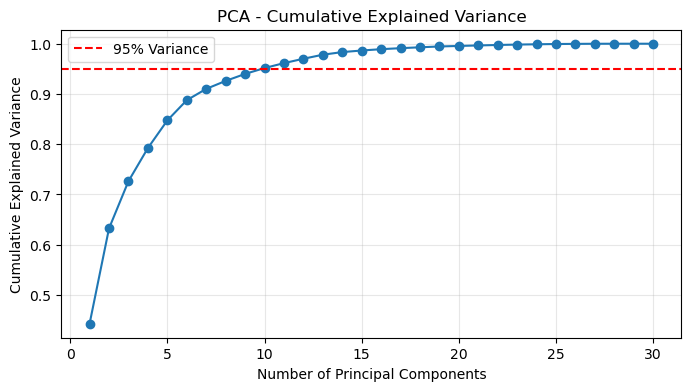

In [8]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")

plt.axhline(y=0.95, color='red', linestyle='--', label='95% Variance')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:
optimal_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Optimal Components:", optimal_components)
print("Original Features:", X_scaled.shape[1])

Optimal Components: 10
Original Features: 30


### Verify our PCA transformation

In [10]:
# Apply PCA with 10 components

pca_optimal = PCA(n_components=10)

X_reduced = pca_optimal.fit_transform(X_scaled)

# Display dimensions
print("Original Dataset:", X_scaled.shape)
print("Reduced Dataset:", X_reduced.shape)

# Check retained variance
print(
    "Total Variance Retained:",
    pca_optimal.explained_variance_ratio_.sum() * 100
)

Original Dataset: (569, 30)
Reduced Dataset: (569, 10)
Total Variance Retained: 95.15688143366667


### Does reducing dimensionality actually make Machine Learning faster, consume less memory, and maintain model performance?

We're going to conduct an experiment with two models:

Model A: Logistic Regression without PCA.
Model B: Logistic Regression with PCA (95% variance retention).

We'll compare:

Accuracy, Precision, Recall and F1-score.
Training time.
Prediction time.
Memory consumption.
Dimensionality reduction.
Experiment: PCA vs. No PCA

In [11]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [12]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

Dataset Shape: (569, 30)
Target Shape: (569,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [16]:
model_without_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

In [17]:
model_with_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(max_iter=5000))
])

## Measure Training Time

In [18]:
# Model A: Without PCA

start_time = time.perf_counter()
model_without_pca.fit(X_train, y_train)
time_without_pca = time.perf_counter() - start_time


# Model B: With PCA
start_time = time.perf_counter()
model_with_pca.fit(X_train, y_train)
time_with_pca = time.perf_counter() - start_time


print("Training Time Without PCA:", time_without_pca)
print("Training Time With PCA:", time_with_pca)

Training Time Without PCA: 0.01271309999992809
Training Time With PCA: 0.009261400000013964


## Measure Prediction Time

In [19]:
# Without PCA

start_time = time.perf_counter()
y_pred_without_pca = model_without_pca.predict(X_test)
prediction_time_without_pca = time.perf_counter() - start_time

# With PCA
start_time = time.perf_counter()
y_pred_with_pca = model_with_pca.predict(X_test)
prediction_time_with_pca = time.perf_counter() - start_time


print("Prediction Time Without PCA:", prediction_time_without_pca)
print("Prediction Time With PCA:", prediction_time_with_pca)

Prediction Time Without PCA: 0.0024023000000852335
Prediction Time With PCA: 0.002199699999891891


# Evaluate the model performance

In [20]:
results = pd.DataFrame({
    "Model": ["Without PCA", "With PCA"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_without_pca),
        accuracy_score(y_test, y_pred_with_pca)
    ],

    "Precision": [
        precision_score(y_test, y_pred_without_pca),
        precision_score(y_test, y_pred_with_pca)
    ],

    "Recall": [
        recall_score(y_test, y_pred_without_pca),
        recall_score(y_test, y_pred_with_pca)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_without_pca),
        f1_score(y_test, y_pred_with_pca)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Without PCA,0.982456,0.986111,0.986111,0.986111
1,With PCA,0.973684,0.985915,0.972222,0.979021


In [21]:
# Original scaled features
X_train_original = model_without_pca.named_steps["scaler"].transform(X_train)

X_test_original = model_without_pca.named_steps["scaler"].transform(X_test)


# PCA transformed features
X_train_pca = model_with_pca.named_steps["pca"].transform(
    model_with_pca.named_steps["scaler"].transform(X_train)
)

X_test_pca = model_with_pca.named_steps["pca"].transform(
    model_with_pca.named_steps["scaler"].transform(X_test)
)


# Calculate memory in MB
memory_without_pca = (
    X_train_original.nbytes + X_test_original.nbytes
) / (1024 ** 2)

memory_with_pca = (
    X_train_pca.nbytes + X_test_pca.nbytes
) / (1024 ** 2)


print("Memory Without PCA:", memory_without_pca, "MB")

print("Memory With PCA:", memory_with_pca, "MB")

Memory Without PCA: 0.1302337646484375 MB
Memory With PCA: 0.0434112548828125 MB


## Compare Dimensionality

In [23]:
print("Original Features:", X_train_original.shape[1])
print("PCA Components:", X_train_pca.shape[1])

reduction = (
    (X_train_original.shape[1] - X_train_pca.shape[1])
    / X_train_original.shape[1]
) * 100

print(f"Dimensionality Reduction: {reduction:.2f}%")

Original Features: 30
PCA Components: 10
Dimensionality Reduction: 66.67%


## Create Final Comparison Table

In [24]:
comparison = pd.DataFrame({
    "Metric": [
        "Training Time (seconds)",
        "Prediction Time (seconds)",
        "Feature Dimensions",
        "Feature Matrix Memory (MB)"
    ],

    "Without PCA": [
        time_without_pca,
        prediction_time_without_pca,
        X_train_original.shape[1],
        memory_without_pca
    ],

    "With PCA": [
        time_with_pca,
        prediction_time_with_pca,
        X_train_pca.shape[1],
        memory_with_pca
    ]
})

comparison

,Metric,Without PCA,With PCA
0,Training Time (seconds),0.012713,0.009261
1,Prediction Time (seconds),0.002402,0.002200
2,Feature Dimensions,30.000000,10.000000
3,Feature Matrix Memory (MB),0.130234,0.043411


# Visualize performance

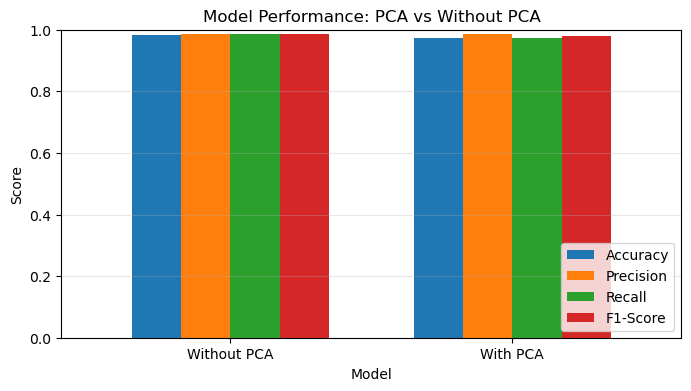

In [27]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(8, 4),
    ylim=(0, 1),
    width=0.7
)

plt.title("Model Performance: PCA vs Without PCA")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.show()

## PCA vs. No PCA using Cross-Validation

In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [29]:
# Build botht the pipelines
model_without_pca = Pipeline([
    ("scaler", StandardScaler()),

    ("classifier", LogisticRegression(
        max_iter=5000
    ))
])

In [30]:
model_without_pca = Pipeline([
    ("scaler", StandardScaler()),

    ("classifier", LogisticRegression(
        max_iter=5000
    ))
])

## Define Evaluation Metrics

In [31]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

## Evaluate model without PCA

In [32]:
start_time = time.perf_counter()

cv_without_pca = cross_validate(
    model_without_pca,
    X,
    y,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    return_estimator=True,
    n_jobs=-1
)

time_without_pca = time.perf_counter() - start_time

print("Cross-validation completed without PCA.")
print(f"Total Time: {time_without_pca:.4f} seconds")

Cross-validation completed without PCA.
Total Time: 3.5314 seconds


## Evaluate model with PCA

In [33]:
start_time = time.perf_counter()

cv_with_pca = cross_validate(
    model_with_pca,
    X,
    y,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    return_estimator=True,
    n_jobs=-1
)

time_with_pca = time.perf_counter() - start_time

print("Cross-validation completed with PCA.")
print(f"Total Time: {time_with_pca:.4f} seconds")

Cross-validation completed with PCA.
Total Time: 2.1225 seconds


## Compare cross-validation results

In [34]:
metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

comparison = []

for metric in metrics:

    without_pca = cv_without_pca[f"test_{metric}"]
    with_pca = cv_with_pca[f"test_{metric}"]

    comparison.append({
        "Metric": metric.capitalize(),

        "Without PCA (Mean)": without_pca.mean(),

        "With PCA (Mean)": with_pca.mean(),

        "Without PCA (Std)": without_pca.std(),

        "With PCA (Std)": with_pca.std()
    })

cv_results = pd.DataFrame(comparison)

cv_results.round(4)

,Metric,Without PCA (Mean),With PCA (Mean),Without PCA (Std),With PCA (Std)
0,Accuracy,0.9737,0.9772,0.0166,0.0070
1,Precision,0.9683,0.9783,0.0290,0.0160
2,Recall,0.9916,0.9860,0.0112,0.0176
3,F1,0.9794,0.9819,0.0127,0.0056
4,Roc_auc,0.9953,0.9949,0.0053,0.0058


In [35]:
final_comparison = pd.DataFrame({
    "Model": [
        "Without PCA",
        "With PCA"
    ],

    "Accuracy": [
        cv_without_pca["test_accuracy"].mean(),
        cv_with_pca["test_accuracy"].mean()
    ],

    "F1-Score": [
        cv_without_pca["test_f1"].mean(),
        cv_with_pca["test_f1"].mean()
    ],

    "ROC-AUC": [
        cv_without_pca["test_roc_auc"].mean(),
        cv_with_pca["test_roc_auc"].mean()
    ],

    "Training Time": [
        cv_without_pca["fit_time"].mean(),
        cv_with_pca["fit_time"].mean()
    ]
})

final_comparison.round(4)

,Model,Accuracy,F1-Score,ROC-AUC,Training Time
0,Without PCA,0.9737,0.9794,0.9953,0.0288
1,With PCA,0.9772,0.9819,0.9949,0.0265
